# Stage 01: Data Understanding
## Hotel Booking Cancellation Prediction

**Goal:** Inspect the dataset structure, attributes, target variable, and initial data quality before EDA and modeling.


### 1. Import Libraries
Importing core data manipulation and plotting libraries.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Pandas display options
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Output folder for figures
fig_dir = Path('results/figures') if Path('results/figures').exists() else Path('../results/figures')
fig_dir.mkdir(parents=True, exist_ok=True)
print('Libraries imported successfully.')


Libraries imported successfully.


### 2. Load the Dataset
Loading `hotel_bookings.csv` and checking its dimensions.


In [2]:
data_path = Path("data/raw/hotel_bookings.csv") if Path("data/raw/hotel_bookings.csv").exists() else Path("../data/raw/hotel_bookings.csv")
df = pd.read_csv(data_path)
print(f"Dataset loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")


Dataset loaded: 119,390 rows, 32 columns


### 3. First Look at the Data
Checking the first rows, last rows, and dataset shape.


In [3]:
# First 5 rows
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.00,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.00,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.00,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.00,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03


In [4]:
# Last 5 rows
df.tail()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,0.00,0,BB,BEL,Offline TA/TO,TA/TO,0,0,0,A,A,0,No Deposit,394.00,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,0.00,0,BB,FRA,Online TA,TA/TO,0,0,0,E,E,0,No Deposit,9.00,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,0.00,0,BB,DEU,Online TA,TA/TO,0,0,0,D,D,0,No Deposit,9.00,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,0.00,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,89.00,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,0.00,0,HB,DEU,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.00,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [5]:
# Number of rows and columns
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Dataset Shape:", df.shape)


Rows: 119390
Columns: 32
Dataset Shape: (119390, 32)


### 4. Data Types and Structure
Inspecting column data types and unique value counts.


In [6]:
# Summary of data types and non-null counts
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [7]:
# Unique values count per column
df.nunique()


hotel                                2
is_canceled                          2
lead_time                          479
arrival_date_year                    3
arrival_date_month                  12
arrival_date_week_number            53
arrival_date_day_of_month           31
stays_in_weekend_nights             17
stays_in_week_nights                35
adults                              14
children                             5
babies                               5
meal                                 5
country                            177
market_segment                       8
distribution_channel                 5
is_repeated_guest                    2
previous_cancellations              15
previous_bookings_not_canceled      73
reserved_room_type                  10
assigned_room_type                  12
booking_changes                     21
deposit_type                         3
agent                              333
company                            352
days_in_waiting_list     

### 5. Descriptive Statistics
Summary statistics for numerical and categorical attributes.


In [8]:
# Numerical summary
numerical_cols = df.select_dtypes(include=np.number).columns
df[numerical_cols].describe().T


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.00,0.37,0.48,0.00,0.00,0.00,1.00,1.00
lead_time,119390.00,104.01,106.86,0.00,18.00,69.00,160.00,737.00
arrival_date_year,119390.00,2016.16,0.71,2015.00,2016.00,2016.00,2017.00,2017.00
arrival_date_week_number,119390.00,27.17,13.61,1.00,16.00,28.00,38.00,53.00
arrival_date_day_of_month,119390.00,15.80,8.78,1.00,8.00,16.00,23.00,31.00
stays_in_weekend_nights,119390.00,0.93,1.00,0.00,0.00,1.00,2.00,19.00
stays_in_week_nights,119390.00,2.50,1.91,0.00,1.00,2.00,3.00,50.00
adults,119390.00,1.86,0.58,0.00,2.00,2.00,2.00,55.00
children,119386.00,0.10,0.40,0.00,0.00,0.00,0.00,10.00
babies,119390.00,0.01,0.10,0.00,0.00,0.00,0.00,10.00


In [9]:
# Categorical summary
categorical_cols = df.select_dtypes(include=['object', 'str']).columns
df[categorical_cols].describe().T


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


### 6. Target Variable: `is_canceled`
Analyzing the balance between canceled (1) and not canceled (0) bookings.


Target counts:
is_canceled
0    75166
1    44224
Name: count, dtype: int64

Cancellation rate: 37.04 %


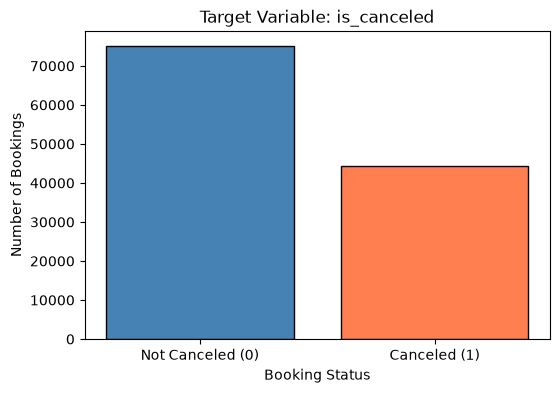

In [10]:
target_counts = df['is_canceled'].value_counts()
print("Target counts:")
print(target_counts)
print()
print("Cancellation rate:", round(df['is_canceled'].mean() * 100, 2), "%")

# Simple bar chart of target variable
plt.figure(figsize=(6, 4))
plt.bar(['Not Canceled (0)', 'Canceled (1)'], target_counts.values, color=['steelblue', 'coral'], edgecolor='black')
plt.title('Target Variable: is_canceled')
plt.xlabel('Booking Status')
plt.ylabel('Number of Bookings')
plt.savefig(fig_dir / 'target_distribution_01.png', bbox_inches='tight')
plt.show()


### 7. Initial Data Quality Checks
Checking for missing values and duplicate records.


In [11]:
# Missing values count and percentage
missing = df.isnull().sum()
missing_summary = pd.DataFrame({
    'Missing Count': missing[missing > 0],
    'Missing (%)': (missing[missing > 0] / len(df) * 100).round(2)
}).sort_values(by='Missing Count', ascending=False)

print("Columns with missing values:")
missing_summary


Columns with missing values:


,Missing Count,Missing (%)
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


In [12]:
# Duplicate rows
duplicates = df.duplicated().sum()
print(f"Duplicate rows: {duplicates:,} ({duplicates / len(df) * 100:.2f}%)")


Duplicate rows: 31,994 (26.80%)


### 8. Target Leakage Warning
`reservation_status` is determined after the booking outcome occurs and directly mirrors `is_canceled`. It must be dropped before training.


In [13]:
# Crosstab showing 100% correlation with target
pd.crosstab(df['reservation_status'], df['is_canceled'], margins=True)


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


### 9. Key Observations & Next Steps

- **Dimensions:** 119,390 rows and 32 columns.
- **Target Variable:** 62.96% non-canceled (75,166) vs. 37.04% canceled (44,224).
- **Missing Data:** `company` (94.31%), `agent` (13.69%), `country` (0.41%), `children` (4 rows).
- **Duplicates:** 31,994 identical rows (26.80%).
- **Target Leakage:** `reservation_status` and `reservation_status_date` must be removed before model training.
- **Next Stage:** Exploratory Data Analysis (`02_exploratory_data_analysis.ipynb`).
